## 1. Imports and Config

In [16]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

artifacts = joblib.load('eda_artifacts.pkl')
df = artifacts['df']
num_features = artifacts['num_features']
iso_anomaly = artifacts['iso_anomaly']

print('Data loaded from EDA.')

Data loaded from EDA.


---
## 2. Data Preparation

In [17]:
df_model = df[num_features + ['Type', 'Target']].copy()
df_model = pd.get_dummies(df_model, columns=['Type'], drop_first=False)

feature_cols = [c for c in df_model.columns if c != 'Target']
X_all = df_model[feature_cols].values
y_all = df_model['Target'].values

X_train_calib, X_test, y_train_calib, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=17, stratify=y_all
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_calib, y_train_calib, test_size=0.176, random_state=17, stratify=y_train_calib
)
# 0.176 * 0.85 ≈ 0.15  ->  train≈70%, calib≈15%, test≈15%

print(f'Train: {X_train.shape[0]} samples')
print(f'Calib: {X_calib.shape[0]} samples')
print(f'Test:  {X_test.shape[0]} samples')
print(f'Train failures: {y_train.sum()} ({y_train.mean()*100:.1f}%)')
print(f'Calib failures: {y_calib.sum()} ({y_calib.mean()*100:.1f}%)')
print(f'Test  failures: {y_test.sum()}  ({y_test.mean()*100:.1f}%)')
print(f'\nFeatures: {len(feature_cols)}\n{feature_cols}')

Train: 7004 samples
Calib: 1496 samples
Test:  1500 samples
Train failures: 237 (3.4%)
Calib failures: 51 (3.4%)
Test  failures: 51  (3.4%)

Features: 8
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


---
## 3. Training and Basic Evaluation

In [18]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=18,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred  = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print('- Classification Report -')
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

roc_auc = roc_auc_score(y_test, y_proba)
avg_prec = average_precision_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')
print(f'Average Precision: {avg_prec:.4f}')

- Classification Report -
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1449
     Failure       1.00      0.37      0.54        51

    accuracy                           0.98      1500
   macro avg       0.99      0.69      0.77      1500
weighted avg       0.98      0.98      0.97      1500

ROC-AUC: 0.9614
Average Precision: 0.8509


---
## 4. Confusion Matrix

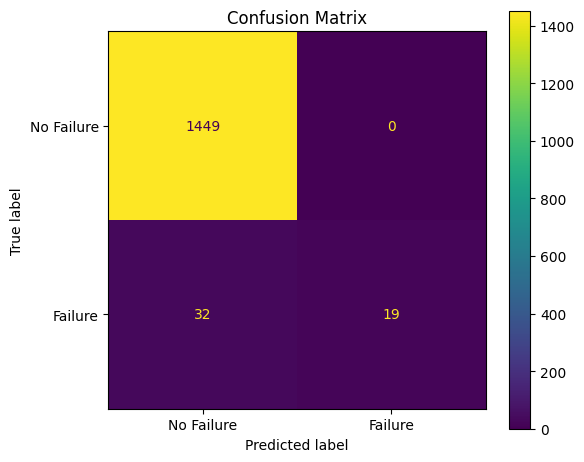


False Alarm Rate: 0.000
Miss Rate: 0.627


In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax)
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\nFalse Alarm Rate: {fp/(fp+tn):.3f}')
print(f'Miss Rate: {fn/(fn+tp):.3f}')

---
## 5. ROC Curve and Precision-Recall Curve

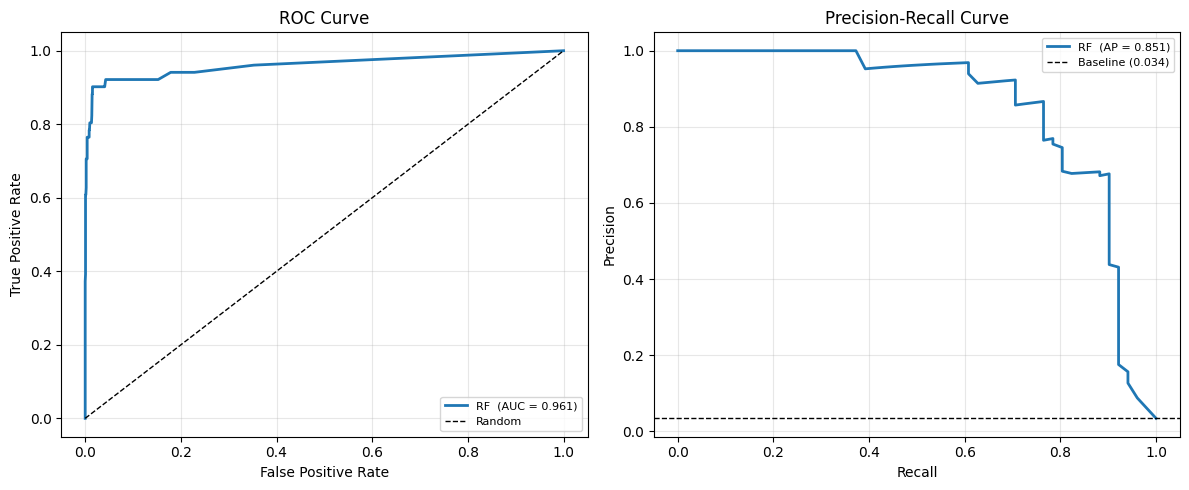

In [20]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f'RF  (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Precision-Recall
ax = axes[1]
ax.plot(rec, prec, lw=2, label=f'RF  (AP = {avg_prec:.3f})')
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 6. Feature Importance

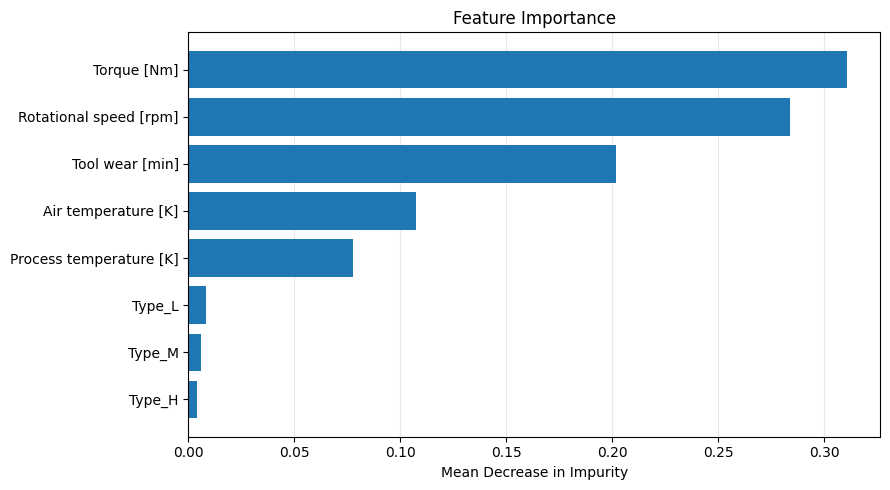

Sorted Feature importances:
 Torque [Nm]:  0.3107
 Rotational speed [rpm]:  0.2840
 Tool wear [min]:  0.2015
 Air temperature [K]:  0.1075
 Process temperature [K]:  0.0777
 Type_L:  0.0083
 Type_M:  0.0061
 Type_H:  0.0041


In [21]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1]
sorted_feats = [feature_cols[i] for i in idx]
sorted_imps = importances[idx]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(sorted_feats[::-1], sorted_imps[::-1])
ax.set_title('Feature Importance')
ax.set_xlabel('Mean Decrease in Impurity')
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print('Sorted Feature importances:')
for f, imp in zip(sorted_feats, sorted_imps):
    print(f' {f:}:  {imp:.4f}')

---
## 7. Cross-validation (Stratified 5-Fold)

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

cv_results = cross_validate(
    rf, X_all, y_all, cv=cv,
    scoring=['roc_auc', 'average_precision', 'f1', 'recall', 'precision'],
    return_train_score=False
)

metrics = {
    'ROC-AUC': cv_results['test_roc_auc'],
    'Avg Precision': cv_results['test_average_precision'],
    'F1 (Failure)': cv_results['test_f1'],
    'Recall (Failure)': cv_results['test_recall'],
    'Precision (Failure)': cv_results['test_precision'],
}

print('- Cross-Validation Results (5-Fold) -')
print(f'{"Metric":<23} {"Mean":>8} {"Std":>8} {"Min":>8} {"Max":>8}')
print('-' * 60)
for name, vals in metrics.items():
    print(f'{name:<25} {vals.mean():>8.4f} {vals.std():>8.4f} {vals.min():>8.4f} {vals.max():>8.4f}')

- Cross-Validation Results (5-Fold) -
Metric                      Mean      Std      Min      Max
------------------------------------------------------------
ROC-AUC                     0.9625   0.0159   0.9375   0.9809
Avg Precision               0.7695   0.0458   0.6886   0.8178
F1 (Failure)                0.5823   0.0514   0.5055   0.6604
Recall (Failure)            0.4277   0.0578   0.3382   0.5147
Precision (Failure)         0.9311   0.0608   0.8485   1.0000


---
## 8. RF Calibration

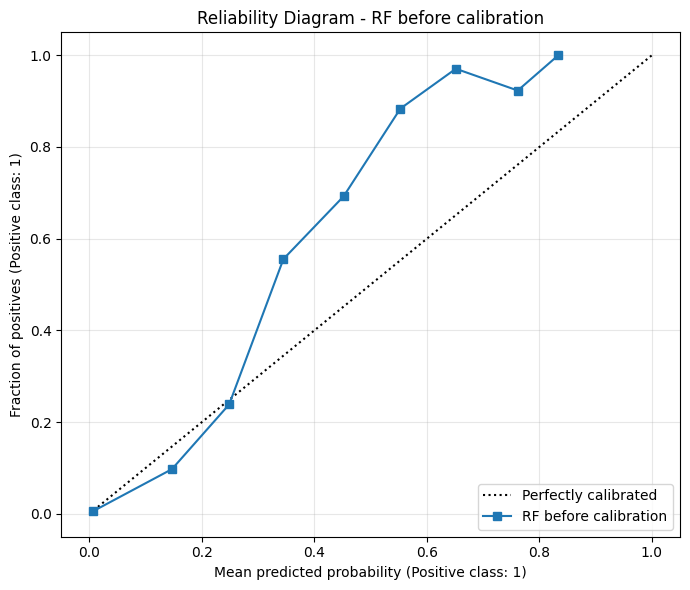

Points above the diagonal -> the model underestimates
Points below the diagonal -> the model overestimates


In [23]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import cross_val_predict

y_proba_cv = cross_val_predict(
    RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=17, n_jobs=-1),
    X_train_calib, y_train_calib,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    method='predict_proba'
)[:, 1]

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_train_calib, y_proba_cv,
    n_bins=10, ax=ax,
    name='RF before calibration'
)
ax.set_title('Reliability Diagram - RF before calibration')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Points above the diagonal -> the model underestimates')
print('Points below the diagonal -> the model overestimates')

---
## 9 . Platt Scaling (Sigmoid) vs Isotonic Regression

In [24]:
base_rf = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', random_state=17, n_jobs=-1
)

base_rf.fit(X_train, y_train)

rf_sigmoid = CalibratedClassifierCV(base_rf, method='sigmoid', cv='prefit')
rf_isotonic = CalibratedClassifierCV(base_rf, method='isotonic', cv='prefit')

rf_sigmoid.fit(X_calib, y_calib)
rf_isotonic.fit(X_calib, y_calib)

y_proba_sigmoid  = rf_sigmoid.predict_proba(X_test)[:, 1]
y_proba_isotonic = rf_isotonic.predict_proba(X_test)[:, 1]

y_proba = base_rf.predict_proba(X_test)[:, 1]

print('Models calibrated. Predicted probabilities on the test set:')
print(f'Original RF   - mean proba: {y_proba.mean():.4f}, std: {y_proba.std():.4f}')
print(f'RF + Sigmoid  - mean proba: {y_proba_sigmoid.mean():.4f}, std: {y_proba_sigmoid.std():.4f}')
print(f'RF + Isotonic - mean proba: {y_proba_isotonic.mean():.4f}, std: {y_proba_isotonic.std():.4f}')
print(f'Actual failure rate (test): {y_test.mean():.4f}')


Models calibrated. Predicted probabilities on the test set:
Original RF   - mean proba: 0.0312, std: 0.1035
RF + Sigmoid  - mean proba: 0.0323, std: 0.1283
RF + Isotonic - mean proba: 0.0335, std: 0.1426
Actual failure rate (test): 0.0340


---
## 10. Reliability Diagram - comparison

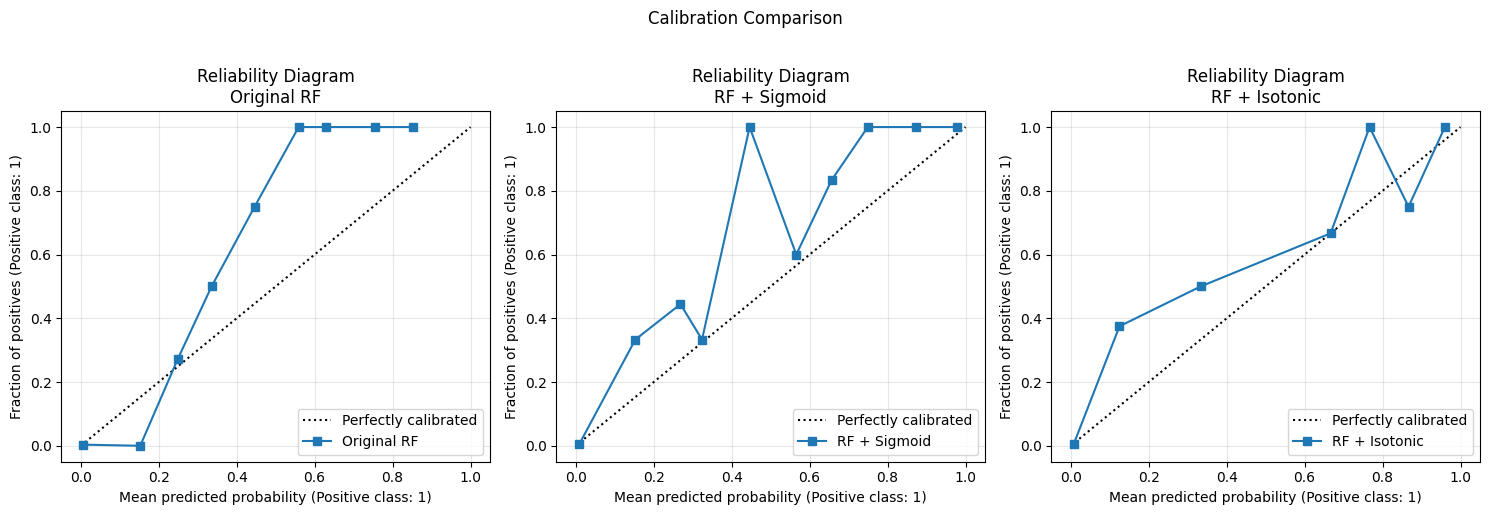

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models_info = [
    (y_proba, 'Original RF', axes[0]),
    (y_proba_sigmoid, 'RF + Sigmoid', axes[1]),
    (y_proba_isotonic, 'RF + Isotonic', axes[2]),
]

for proba, name, ax in models_info:
    CalibrationDisplay.from_predictions(
        y_test, proba, n_bins=10, ax=ax, name=name
    )
    ax.set_title(f'Reliability Diagram\n{name}')
    ax.grid(True, alpha=0.3)

plt.suptitle('Calibration Comparison', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

---
## 11. Brier Score

- Brier Score -
Baseline (naive): 0.032844
Original RF: 0.014332  (skill: +0.5636)
RF + Sigmoid: 0.011579  (skill: +0.6474)
RF + Isotonic: 0.012169  (skill: +0.6295)


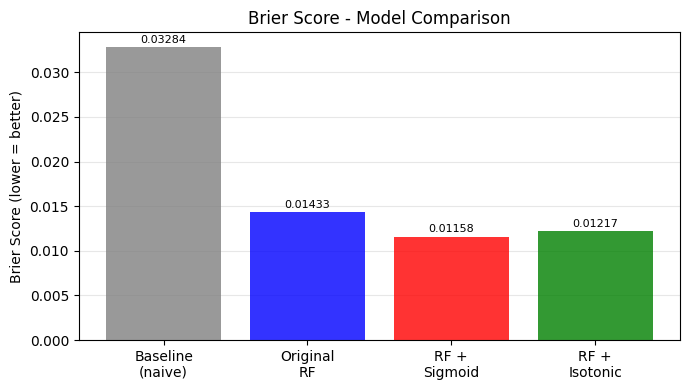

In [26]:
from sklearn.metrics import brier_score_loss

brier_orig = brier_score_loss(y_test, y_proba)
brier_sigmoid = brier_score_loss(y_test, y_proba_sigmoid)
brier_isotonic = brier_score_loss(y_test, y_proba_isotonic)

brier_baseline = brier_score_loss(
    y_test,
    np.full_like(y_test, y_test.mean(), dtype=float)
)

def brier_skill(brier, baseline):
    return 1 - brier / baseline

print('- Brier Score -')
print(f'Baseline (naive): {brier_baseline:.6f}')
print(f'Original RF: {brier_orig:.6f}  (skill: {brier_skill(brier_orig, brier_baseline):+.4f})')
print(f'RF + Sigmoid: {brier_sigmoid:.6f}  (skill: {brier_skill(brier_sigmoid, brier_baseline):+.4f})')
print(f'RF + Isotonic: {brier_isotonic:.6f}  (skill: {brier_skill(brier_isotonic, brier_baseline):+.4f})')

fig, ax = plt.subplots(figsize=(7, 4))

names = [
    'Baseline\n(naive)',
    'Original\nRF',
    'RF +\nSigmoid',
    'RF +\nIsotonic'
]

scores = [
    brier_baseline,
    brier_orig,
    brier_sigmoid,
    brier_isotonic
]

colors = ['gray', 'blue', 'red', 'green']

bars = ax.bar(names, scores, color=colors, alpha=0.8)

for bar, val in zip(bars, scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.0005,
        f'{val:.5f}',
        ha='center',
        fontsize=8
    )

ax.set_title('Brier Score - Model Comparison')
ax.set_ylabel('Brier Score (lower = better)')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

---
## 12. AUC / AP Comparison - Calibrated Models

Model                ROC-AUC   Avg Prec     Brier
--------------------------------------------------
Original RF           0.9617     0.8424  0.014332
RF + Sigmoid          0.9617     0.8424  0.011579
RF + Isotonic         0.9606     0.7899  0.012169


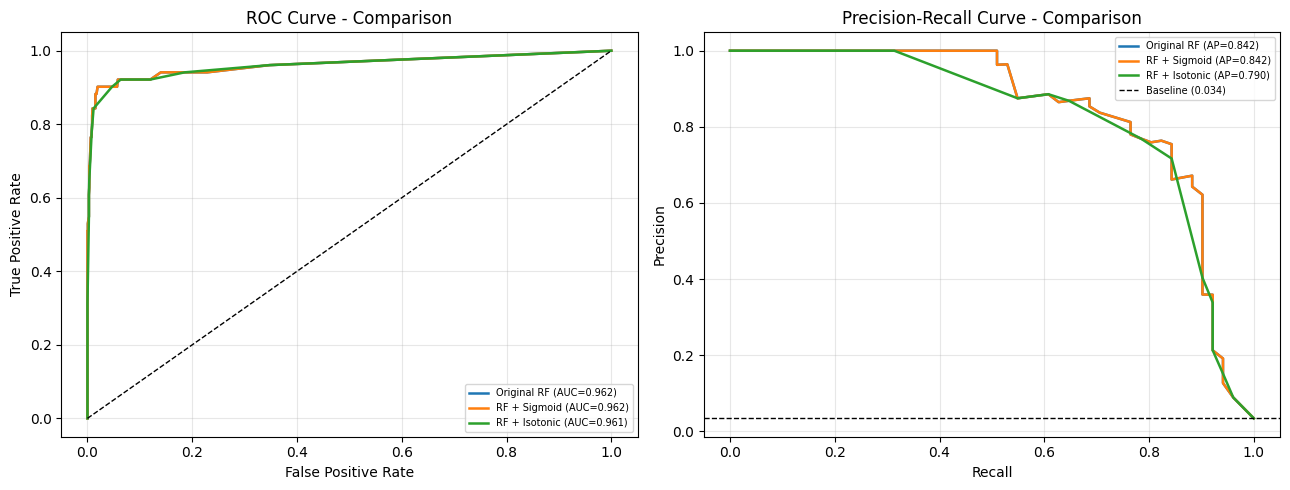

In [27]:
results = {
    'Original RF': (
        y_proba,
        roc_auc_score(y_test, y_proba),
        average_precision_score(y_test, y_proba)
    ),
    'RF + Sigmoid': (
        y_proba_sigmoid,
        roc_auc_score(y_test, y_proba_sigmoid),
        average_precision_score(y_test, y_proba_sigmoid)
    ),
    'RF + Isotonic': (
        y_proba_isotonic,
        roc_auc_score(y_test, y_proba_isotonic),
        average_precision_score(y_test, y_proba_isotonic)
    ),
}

print(f'{"Model":<18} {"ROC-AUC":>9} {"Avg Prec":>10} {"Brier":>9}')
print('-' * 50)

briery = [brier_orig, brier_sigmoid, brier_isotonic]

for (name, (_, auc, ap)), brier in zip(results.items(), briery):
    print(f'{name:<18} {auc:>9.4f} {ap:>10.4f} {brier:>9.6f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, (proba, auc, ap) in results.items():
    fpr_i, tpr_i, _ = roc_curve(y_test, proba)
    axes[0].plot(
        fpr_i,
        tpr_i,
        lw=1.8,
        label=f'{name} (AUC={auc:.3f})'
    )

    prec_i, rec_i, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(
        rec_i,
        prec_i,
        lw=1.8,
        label=f'{name} (AP={ap:.3f})'
    )

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('ROC Curve - Comparison')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=7)
axes[0].grid(True, alpha=0.3)

axes[1].axhline(
    y_test.mean(),
    color='k',
    linestyle='--',
    lw=1,
    label=f'Baseline ({y_test.mean():.3f})'
)

axes[1].set_title('Precision-Recall Curve - Comparison')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(fontsize=7)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 13. Predicted Probability Distribution

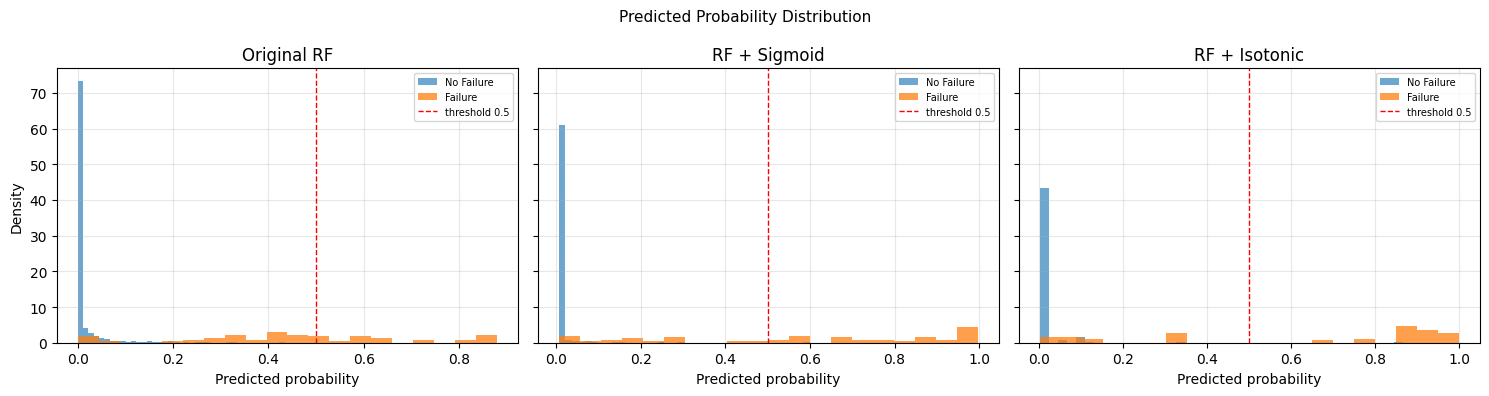

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

plot_data = [
    (y_proba,          'Original RF',   axes[0]),
    (y_proba_sigmoid,  'RF + Sigmoid',    axes[1]),
    (y_proba_isotonic, 'RF + Isotonic',   axes[2]),
]

for proba, name, ax in plot_data:
    ax.hist(proba[y_test==0], bins=40, alpha=0.65, density=True, label='No Failure')
    ax.hist(proba[y_test==1], bins=20, alpha=0.75, density=True, label='Failure')
    ax.axvline(0.5, color='red', linestyle='--', lw=1, label='threshold 0.5')
    ax.set_title(name)
    ax.set_xlabel('Predicted probability')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Density')
plt.suptitle('Predicted Probability Distribution', fontsize=11)
plt.tight_layout()
plt.show()

---
## 14. Decision Threshold Optimization

Selected model for threshold analysis: RF + Sigmoid


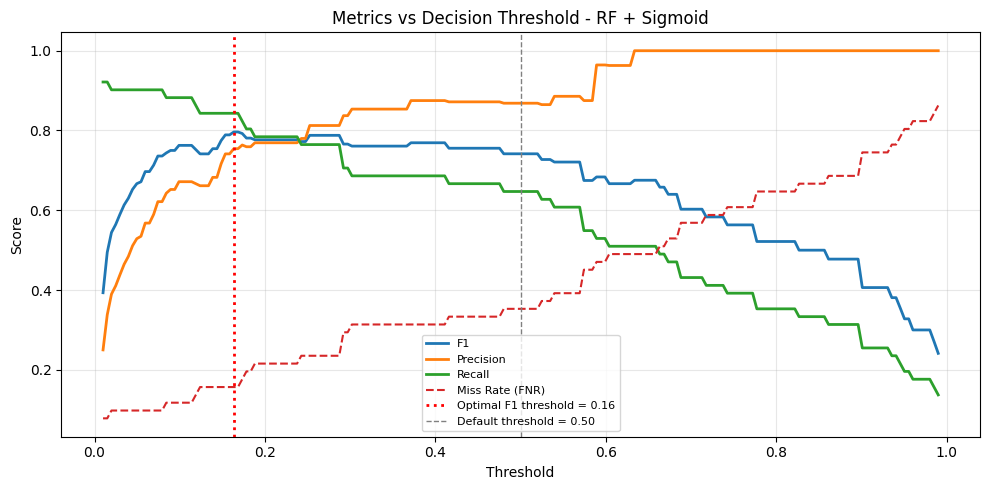


- Default threshold (0.50) -
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1449
     Failure       0.87      0.65      0.74        51

    accuracy                           0.98      1500
   macro avg       0.93      0.82      0.87      1500
weighted avg       0.98      0.98      0.98      1500


- Optimal F1 threshold (0.16) -
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1449
     Failure       0.75      0.84      0.80        51

    accuracy                           0.99      1500
   macro avg       0.87      0.92      0.89      1500
weighted avg       0.99      0.99      0.99      1500


- Metric Changes Comparison -
Metric                    Threshold 0.50  Opt. Threshold     Change
------------------------------------------------------------
F1-score                        0.7416       0.7963    +0.0547
Precision                       0.8684       0.7544    -0.11

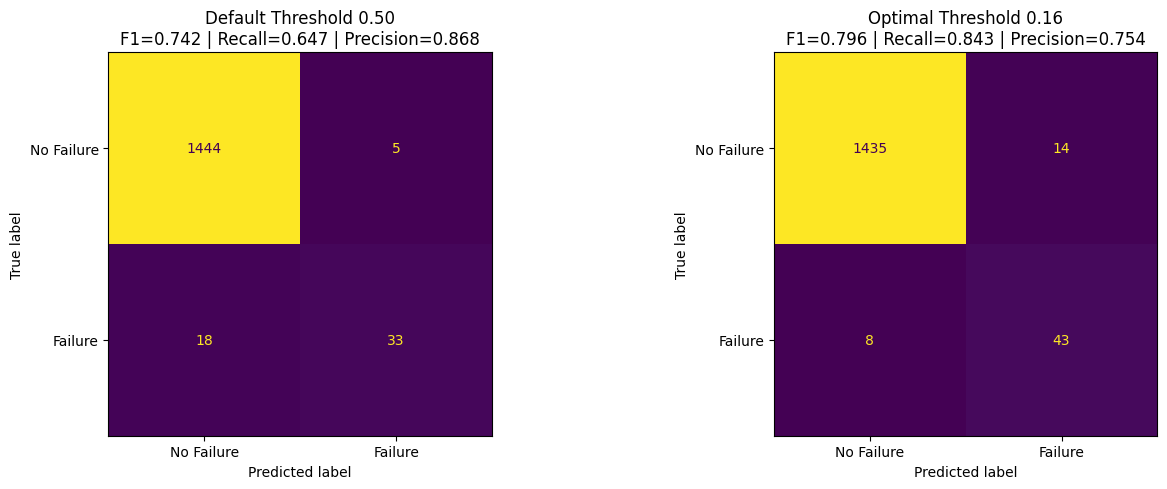

In [29]:
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

best_proba = y_proba_isotonic if brier_isotonic <= brier_sigmoid else y_proba_sigmoid
best_name  = 'RF + Isotonic'  if brier_isotonic <= brier_sigmoid else 'RF + Sigmoid'
print(f'Selected model for threshold analysis: {best_name}')

thresholds = np.linspace(0.01, 0.99, 199)
f1s, precs, recs, fnrs = [], [], [], []

for t in thresholds:
    y_t = (best_proba >= t).astype(int)
    f1s.append(f1_score(y_test, y_t, zero_division=0))
    precs.append(precision_score(y_test, y_t, zero_division=0))
    recs.append(recall_score(y_test, y_t, zero_division=0))
    cm_t = confusion_matrix(y_test, y_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel() if cm_t.size == 4 else (0,0,0,0)
    fnrs.append(fn_t / (fn_t + tp_t + 1e-9))

best_t_idx = np.argmax(f1s)
best_t = thresholds[best_t_idx]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, f1s,   lw=2, label='F1')
ax.plot(thresholds, precs, lw=2, label='Precision')
ax.plot(thresholds, recs,  lw=2, label='Recall')
ax.plot(thresholds, fnrs,  lw=1.5, linestyle='--', label='Miss Rate (FNR)')
ax.axvline(best_t, color='red', linestyle=':', lw=2, label=f'Optimal F1 threshold = {best_t:.2f}')
ax.axvline(0.5, color='gray', linestyle='--', lw=1, label='Default threshold = 0.50')
ax.set_title(f'Metrics vs Decision Threshold - {best_name}')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'\n- Default threshold (0.50) -')
y_default = (best_proba >= 0.50).astype(int)
print(classification_report(y_test, y_default, target_names=['No Failure', 'Failure']))

print(f'\n- Optimal F1 threshold ({best_t:.2f}) -')
y_optimal = (best_proba >= best_t).astype(int)
print(classification_report(y_test, y_optimal, target_names=['No Failure', 'Failure']))

print("\n- Metric Changes Comparison -")

f1_def = f1_score(y_test, y_default, zero_division=0)
prec_def = precision_score(y_test, y_default, zero_division=0)
rec_def = recall_score(y_test, y_default, zero_division=0)

f1_opt = f1_score(y_test, y_optimal, zero_division=0)
prec_opt = precision_score(y_test, y_optimal, zero_division=0)
rec_opt = recall_score(y_test, y_optimal, zero_division=0)

cm_def = confusion_matrix(y_test, y_default)
tn_def, fp_def, fn_def, tp_def = cm_def.ravel()
fnr_def = fn_def / (fn_def + tp_def)

cm_opt = confusion_matrix(y_test, y_optimal)
tn_opt, fp_opt, fn_opt, tp_opt = cm_opt.ravel()
fnr_opt = fn_opt / (fn_opt + tp_opt)

print(f"{'Metric':<25} {'Threshold 0.50':>14} {'Opt. Threshold':>15} {'Change':>10}")
print("-" * 60)
print(f"{'F1-score':<25} {f1_def:>12.4f} {f1_opt:>12.4f} {f1_opt - f1_def:>+10.4f}")
print(f"{'Precision':<25} {prec_def:>12.4f} {prec_opt:>12.4f} {prec_opt - prec_def:>+10.4f}")
print(f"{'Recall':<25} {rec_def:>12.4f} {rec_opt:>12.4f} {rec_opt - rec_def:>+10.4f}")
print(f"{'Miss Rate (FNR)':<25} {fnr_def:>12.4f} {fnr_opt:>12.4f} {fnr_opt - fnr_def:>+10.4f}")
print(f"{'True Positives':<25} {tp_def:>12} {tp_opt:>12} {tp_opt - tp_def:>+10}")
print(f"{'False Positives':<25} {fp_def:>12} {fp_opt:>12} {fp_opt - fp_def:>+10}")
print(f"{'False Negatives':<25} {fn_def:>12} {fn_opt:>12} {fn_opt - fn_def:>+10}")
print(f"{'True Negatives':<25} {tn_def:>12} {tn_opt:>12} {tn_opt - tn_def:>+10}")

print("\nInterpretation:")
print("The optimal threshold improved failure detection: the F1-score increased by 0.0547 and recall rose by 0.1961 (from 64.7% to 84.3%), while the miss rate dropped by the same margin. This gain required accepting a precision decrease of 0.1140, as false positives increased from 5 to 14. The trade-off is favorable in this context, since the cost of undetected failures substantially outweighs the cost of additional false alarms.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

disp_def = ConfusionMatrixDisplay(cm_def, display_labels=['No Failure', 'Failure'])
disp_def.plot(ax=axes[0], colorbar=False)
axes[0].set_title(f'Default Threshold 0.50\nF1={f1_def:.3f} | Recall={rec_def:.3f} | Precision={prec_def:.3f}')

disp_opt = ConfusionMatrixDisplay(cm_opt, display_labels=['No Failure', 'Failure'])
disp_opt.plot(ax=axes[1], colorbar=False)
axes[1].set_title(f'Optimal Threshold {best_t:.2f}\nF1={f1_opt:.3f} | Recall={rec_opt:.3f} | Precision={prec_opt:.3f}')

plt.tight_layout()
plt.show()

---
## 15. Summary

In [32]:
print('Summary - RF Calibration')
print(f'{"Model":<18} {"ROC-AUC":>9} {"Brier":>10} {"Skill":>8}')
print(f'{"-"*48}')
for (name, (_, auc, _)), brier in zip(results.items(), briery):
    skill = 1 - brier / brier_baseline
    print(f'{name:<18} {auc:>9.4f} {brier:>10.6f} {skill:>8.4f}')
print()
print(f'Selected final model: {best_name}')
print(f'Optimal decision threshold (max F1): {best_t:.2f}')

Summary - RF Calibration
Model                ROC-AUC      Brier    Skill
------------------------------------------------
Original RF           0.9617   0.014332   0.5636
RF + Sigmoid          0.9617   0.011579   0.6474
RF + Isotonic         0.9606   0.012169   0.6295

Selected final model: RF + Sigmoid
Optimal decision threshold (max F1): 0.16
